# The Oakland Rent Squeeze: Calculation Notebook
### Building a utility function, one step at a time

**INFSCI/PS 0702 · Companion to the case study** · Reading: *The Model Thinker*, Chapter 4

---

This notebook shows **how** to do every calculation in the case study. It does **not** give you the answers to the case questions. You will still write every answer yourself, on your worksheet.

Each step of the case has two kinds of cells here:

| Cell type | What it does |
|---|---|
| 🔎 **Worked example** | Demonstrates a calculation from start to finish, using a *different* student (**Jordan**, from lecture) or practice data. The numbers are deliberately not Dev's. Read the comments and the output. |
| ✏️ **Your turn** | Sets up the *same* calculation for Dev. Every case-specific number is `None`. You copy the numbers from the case study, run the cell, and then interpret the result yourself. |

The notebook will calculate, but it will never tell you what the numbers *mean*. That part is yours.

### How to run a notebook
- Click a code cell and press **Shift + Enter** to run it. Output appears underneath.
- Run the cells **in order, from top to bottom**. Later cells use tools built in earlier cells.
- If a ✏️ cell prints **⏸ Waiting for you**, it is telling you which `None` values still need numbers.
- If things get confusing, use **Kernel → Restart & Run All** to start fresh.

### Which cells help with which questions

| Notebook section | Case questions it supports |
|---|---|
| Step 1: Rule-based predictions | Q1 |
| Step 3: Checking preferences | Q5, Q6 |
| Step 4: Turning preferences into numbers | Q9 |
| Step 5: The utility function and budget | Q13 (and background for Q12) |
| Step 6: Estimating the weight *a* | Q14, Q15 (and background for Q16) |
| Step 7: Finding the best apartment | Q17, Q18, Q19, Q20 |
| Step 8: "What if?" | Q21, Q23, Q24, Q25 |
| Step 9: Testing and extremes | Q26, Q29 |

Step 2 and the discussion questions (Q2–Q4, Q7–Q8, Q10–Q12, Q16, Q22, Q27–Q28, Q30) are about reasoning, not arithmetic. The notebook gives you numbers to reason *with*, but the reasoning is up to you.

### Notation used throughout

| Symbol | Meaning | Units |
|---|---|---|
| `I` | monthly budget (income) for rent plus everything else | dollars per month |
| `p` | rent price per square foot | dollars per sq ft per month |
| `H` | housing: apartment size | square feet |
| `C` | consumption: money left for everything except rent | dollars per month |
| `a` | weight on housing in the utility function (between 0 and 1) | none |
| `U` | utility score | **none** (only the ranking matters) |

## Python in 60 seconds

You do not need to be a programmer to use this notebook. Here is everything you need to recognize:

| You will see | It means |
|---|---|
| `budget = 3000` | Store the number 3000 under the name `budget`. |
| `rent / budget` | Division. Also `+`, `-`, `*` (multiply). |
| `900 ** 0.6` | 900 raised to the power 0.6 (the x<sup>y</sup> key on a calculator). |
| `None` | "Nothing here yet." In ✏️ cells, replace `None` with a number. |
| `# a comment` | Anything after `#` is a note for humans; Python ignores it. |
| `def name(...):` | Defines a reusable tool (a *function*). You run it later by writing its name. |

The setup cell below loads two standard libraries (`pandas` for tables, `matplotlib` for charts) and defines two small helpers used everywhere.

In [1]:
# ── Setup: run this cell first ──────────────────────────────────────────
import pandas as pd                 # tables
import matplotlib.pyplot as plt     # charts

# Show decimals with two places and thousands separators in tables
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams["text.parse_math"] = False   # so "$" in chart titles prints as a dollar sign

def ready(**values):
    """Check that every input in a ✏️ cell has been filled in.

    Returns True when no value is None. Otherwise prints which ones are
    still missing and returns False, so the cell skips its calculation
    instead of crashing.
    """
    missing = [name for name, v in values.items()
               if v is None or (isinstance(v, (list, tuple)) and any(
                   x is None or (isinstance(x, tuple) and None in x) for x in v))]
    if missing:
        print("⏸ Waiting for you: fill in", ", ".join(missing), "then re-run this cell.")
        return False
    return True

def money(x):
    """Format a number as dollars, e.g. 1234.5 -> '$1,234.50'."""
    return f"${x:,.2f}"

print("Setup complete.")

Setup complete.


## Math toolkit, in code

The case study's Math Toolkit lists four tools. Here is each one in Python, using practice numbers.

In [2]:
# 🔎 WORKED EXAMPLE — the four toolkit operations, with practice numbers

# 1. Share (percent): part ÷ whole
part, whole = 450, 1800
share = part / whole
print(f"1. Share: {part} ÷ {whole} = {share:.2f}, which is {share:.0%}")

# 2. Average: add up, then divide by how many
numbers = [31, 35, 33]
average = sum(numbers) / len(numbers)
print(f"2. Average of {numbers}: {sum(numbers)} ÷ {len(numbers)} = {average:.2f}")

# 3. Decimal exponents: ** is the x^y key
print(f"3. 2500 ** 0.5 = {2500 ** 0.5:.2f}   (a power of 0.5 is a square root)")
print(f"   8 ** (1/3)  = {8 ** (1/3):.2f}    (a power of 1/3 is a cube root)")

# 4. Maximize: find the biggest number in a list
scores = [12.1, 15.8, 14.2]
print(f"4. Largest of {scores} is {max(scores)}")

1. Share: 450 ÷ 1800 = 0.25, which is 25%
2. Average of [31, 35, 33]: 99 ÷ 3 = 33.00
3. 2500 ** 0.5 = 50.00   (a power of 0.5 is a square root)
   8 ** (1/3)  = 2.00    (a power of 1/3 is a cube root)
4. Largest of [12.1, 15.8, 14.2] is 15.8


In [3]:
# ✏️ YOUR TURN — check your exponent skills
# The Math Toolkit in the case study tells you what 900 raised to 0.6 should be.
# Type the calculation after the = sign (replace None), run, and compare.

my_check = None     # e.g.  some_number ** some_power

if ready(my_check=my_check):
    print(f"Your result: {my_check:.2f}")

⏸ Waiting for you: fill in my_check then re-run this cell.


---
# Step 1: Choose your kind of model

A **rule-based** person follows a rule of thumb. To predict what they do, you do not need a utility function at all; you just apply the rule. The case has two kinds of rules:

- **Fixed size** ("I always renew my lease"): the size stays the same, so **rent = size × price**.
- **Fixed rent** ("I always spend $X on rent"): the rent stays the same, so **size = rent ÷ price**.

Either way, **money left over = budget − rent**.

Below, each rule becomes a small function so we can reuse it later (Step 8).

In [4]:
def fixed_size_rule(size, price, budget):
    """Predict a person who keeps the same apartment size no matter what."""
    rent = size * price                  # rent = size × price
    return {"size (sq ft)": size,
            "rent": rent,
            "left for everything else": budget - rent}

def fixed_rent_rule(rent, price, budget):
    """Predict a person who always spends the same dollar amount on rent."""
    size = rent / price                  # size = rent ÷ price
    return {"size (sq ft)": size,
            "rent": rent,
            "left for everything else": budget - rent}

### 🔎 Worked example: Jordan's housemates

From lecture: **Jordan** has a budget of **$3,000** a month, and rent is **$2.00** per sq ft. Jordan has two housemates who use rules:

- **Casey** always renews, keeping a **500 sq ft** apartment.
- **Taylor** always spends **$1,000** on rent.

Suppose rent rises to **$2.40** per sq ft. What does each rule predict?

In [5]:
# 🔎 WORKED EXAMPLE — rule-based predictions for Jordan's housemates
jordan_budget = 3000      # dollars per month
new_price     = 2.40      # dollars per sq ft (after the increase)

casey = fixed_size_rule(size=500,  price=new_price, budget=jordan_budget)
taylor = fixed_rent_rule(rent=1000, price=new_price, budget=jordan_budget)

worked_rules = pd.DataFrame([casey, taylor], index=["Casey (fixed size)", "Taylor (fixed rent)"])
display(worked_rules)

# Show the arithmetic behind each row
print("Casey:  rent = 500 × $2.40 =", money(500 * new_price),
      "| left over =", money(jordan_budget), "−", money(500 * new_price), "=", money(jordan_budget - 500 * new_price))
print("Taylor: size = $1,000 ÷ $2.40 =", f"{1000 / new_price:.1f} sq ft",
      "| left over =", money(jordan_budget), "− $1,000.00 =", money(jordan_budget - 1000))

,size (sq ft),rent,left for everything else
Casey (fixed size),500.00,"1,200.00","1,800.00"
Taylor (fixed rent),416.67,"1,000.00","2,000.00"


Casey:  rent = 500 × $2.40 = $1,200.00 | left over = $3,000.00 − $1,200.00 = $1,800.00
Taylor: size = $1,000 ÷ $2.40 = 416.7 sq ft | left over = $3,000.00 − $1,000.00 = $2,000.00


In [6]:
# ✏️ YOUR TURN — Riley and Sam (supports Q1)
# Copy the numbers from Step 1 of the case study. Replace every None.

dev_budget  = None   # each housemate's monthly budget, in dollars
new_price_1 = None   # the NEW rent per square foot
riley_size  = None   # the apartment size Riley keeps renewing (sq ft)
sam_rent    = None   # the monthly rent Sam always pays (dollars)

if ready(dev_budget=dev_budget, new_price_1=new_price_1, riley_size=riley_size, sam_rent=sam_rent):
    riley = fixed_size_rule(riley_size, new_price_1, dev_budget)
    sam   = fixed_rent_rule(sam_rent,   new_price_1, dev_budget)
    display(pd.DataFrame([riley, sam], index=["Riley", "Sam"]))

⏸ Waiting for you: fill in dev_budget, new_price_1, riley_size, sam_rent then re-run this cell.


> **Before you continue:** answer Q2 on your worksheet. Write down your guess about Dev *before* the model tells you anything.

---
# Step 2: State your assumptions

There are no calculations in this step. Work through Q3 and Q4 on your worksheet. Keep your list of broken assumptions handy, because in Step 9 you will see which of them matter.

---
# Step 3: Check that the preferences make sense

### Representing preferences as data
Each interview answer says "this option beat that one." We store answers in a Python *dictionary* that maps the **answer number** to a pair **(preferred, other)**:

```python
answers = {1: ("Chocolate", "Vanilla"),   # answer 1: Chocolate beats Vanilla
           2: ("Vanilla", "Strawberry")}  # answer 2: Vanilla beats Strawberry
```

### What we will compute
1. **A picture** of the answers: an arrow from each winner to the option it beat.
2. **Loops** (transitivity violations): any chain where x beats y, y beats z, *and* z beats x.
3. **A ranking by wins**: count how often each option won, then check whether that ranking agrees with *every* answer.
4. **A money pump simulation**: what happens if someone charges a fee for each swap to something the person prefers.

In [7]:
import math

def draw_preferences(answers, title="Preferences"):
    """Draw each option as a dot and an arrow from winner to loser.
    Each arrow is labeled with its answer number."""
    options = sorted({x for pair in answers.values() for x in pair})
    n = len(options)
    # place options evenly around a circle
    pos = {o: (math.cos(2*math.pi*k/n + math.pi/2), math.sin(2*math.pi*k/n + math.pi/2))
           for k, o in enumerate(options)}
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    for num, (win, lose) in answers.items():
        (x1, y1), (x2, y2) = pos[win], pos[lose]
        # slightly curved arrows so crossing diagonals stay readable
        ax.annotate("", xy=(x2*0.82 + x1*0.18, y2*0.82 + y1*0.18),
                    xytext=(x1*0.82 + x2*0.18, y1*0.82 + y2*0.18),
                    arrowprops=dict(arrowstyle="-|>", color="#003594", lw=1.6,
                                    connectionstyle="arc3,rad=0.15"))
        # label each arrow with its answer number, a little past the winner's end
        lx, ly = x1*0.68 + x2*0.32, y1*0.68 + y2*0.32
        ax.text(lx, ly, str(num), fontsize=9, color="#B07A00", fontweight="bold",
                ha="center", va="center", bbox=dict(fc="white", ec="#B07A00", pad=1.5, lw=0.5))
    for o, (x, y) in pos.items():
        ax.scatter(x, y, s=1500, color="#EEF2FA", edgecolor="#003594", zorder=3)
        ax.text(x, y, o, ha="center", va="center", fontsize=8, zorder=4)
    ax.set_title(title); ax.set_xlim(-1.4, 1.4); ax.set_ylim(-1.4, 1.4); ax.axis("off")
    plt.show()

def find_loops(answers):
    """List every three-option loop (x beats y, y beats z, z beats x),
    together with the answer numbers that create it."""
    beats = {(w, l): num for num, (w, l) in answers.items()}
    options = sorted({x for pair in beats for x in pair})
    seen, loops = set(), []
    for x in options:
        for y in options:
            for z in options:
                if (x, y) in beats and (y, z) in beats and (z, x) in beats:
                    key = frozenset([x, y, z])
                    if key not in seen:
                        seen.add(key)
                        loops.append(f"{x} beats {y} (answer {beats[(x, y)]}) → "
                                     f"{y} beats {z} (answer {beats[(y, z)]}) → "
                                     f"{z} beats {x} (answer {beats[(z, x)]})")
    if loops:
        print(f"Found {len(loops)} loop(s):")
        for line in loops:
            print("  •", line)
    else:
        print("No loops found: these answers are transitive.")
    return loops

def rank_by_wins(answers):
    """Rank options by number of wins, then check the ranking against every answer."""
    options = sorted({x for pair in answers.values() for x in pair})
    wins = {o: sum(1 for w, _ in answers.values() if w == o) for o in options}
    ranking = sorted(options, key=lambda o: -wins[o])
    print("Wins:", wins)
    print("Ranking by wins (best → worst):", " > ".join(ranking))
    disagreements = [num for num, (w, l) in answers.items() if ranking.index(w) > ranking.index(l)]
    if disagreements:
        print(f"⚠ This ranking disagrees with {len(disagreements)} of the answers.")
    else:
        print("✓ This ranking agrees with every answer.")
    return ranking

### 🔎 Worked example A: consistent preferences (ice cream)
Four flavors, six answers. Do they hang together?

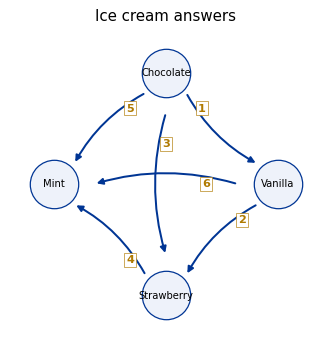

No loops found: these answers are transitive.
Wins: {'Chocolate': 3, 'Mint': 0, 'Strawberry': 1, 'Vanilla': 2}
Ranking by wins (best → worst): Chocolate > Vanilla > Strawberry > Mint
✓ This ranking agrees with every answer.


In [8]:
# 🔎 WORKED EXAMPLE A — ice cream preferences with no loop
ice_cream = {
    1: ("Chocolate", "Vanilla"),
    2: ("Vanilla", "Strawberry"),
    3: ("Chocolate", "Strawberry"),
    4: ("Strawberry", "Mint"),
    5: ("Chocolate", "Mint"),
    6: ("Vanilla", "Mint"),
}
draw_preferences(ice_cream, "Ice cream answers")
find_loops(ice_cream)
rank_by_wins(ice_cream);

### 🔎 Worked example B: a loop (Sam's sodas, from lecture)
Sam prefers Coke to Sprite, Pepsi to Coke, and Sprite to Pepsi.

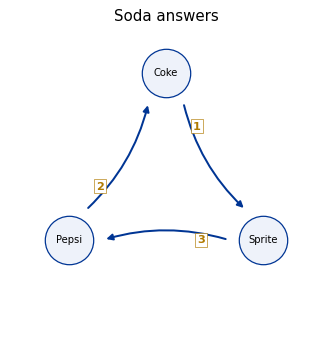

Found 1 loop(s):
  • Coke beats Sprite (answer 1) → Sprite beats Pepsi (answer 3) → Pepsi beats Coke (answer 2)
Wins: {'Coke': 1, 'Pepsi': 1, 'Sprite': 1}
Ranking by wins (best → worst): Coke > Pepsi > Sprite
⚠ This ranking disagrees with 2 of the answers.


In [9]:
# 🔎 WORKED EXAMPLE B — Sam's soda preferences contain a loop
sodas = {
    1: ("Coke", "Sprite"),
    2: ("Pepsi", "Coke"),
    3: ("Sprite", "Pepsi"),
}
draw_preferences(sodas, "Soda answers")
find_loops(sodas)
rank_by_wins(sodas);   # with a loop, no ranking can agree with every answer

### The money pump
If someone's answers contain a loop, a trader can keep offering swaps to something they "prefer", charging a fee each time. The function below simulates that. At each step it looks for an option the person prefers to what they are holding; if there is none, the pump stops.

In [10]:
def money_pump(answers, start, fee, max_swaps=6):
    """Simulate a trader who keeps offering a swap to something the person
    prefers to what they hold, charging `fee` for each swap.

    The trader is clever: if some chain of 'upgrades' leads back to the
    starting option, the trader follows that chain (so it can repeat forever).
    Otherwise the trader just keeps offering upgrades until none are left."""
    # upgrades[x] = list of options the person prefers to x
    upgrades = {}
    for w, l in answers.values():
        upgrades.setdefault(l, []).append(w)

    # Breadth-first search for the shortest chain of upgrades that returns to `start`
    paths, cycle = [[start]], None
    while paths and cycle is None:
        new_paths = []
        for path in paths:
            for nxt in upgrades.get(path[-1], []):
                if nxt == start:
                    cycle = path[1:] + [start]; break
                if nxt not in path:
                    new_paths.append(path + [nxt])
            if cycle: break
        paths = new_paths

    holding, paid = start, 0.0
    print(f"Start: holding {holding}, paid {money(paid)}")
    for step in range(1, max_swaps + 1):
        if cycle:
            holding = cycle[(step - 1) % len(cycle)]
        else:
            better = upgrades.get(holding, [])
            if not better:
                print(f"Stop: nothing beats {holding}, so no more swaps are accepted.")
                break
            holding = better[0]
        paid += fee
        print(f"Swap {step}: trades up to {holding}, total paid {money(paid)}")
    return holding, paid

print("— Sam and the sodas —")
money_pump(sodas, start="Sprite", fee=0.25, max_swaps=6)
print("\n— The ice cream fan —")
money_pump(ice_cream, start="Mint", fee=0.25, max_swaps=6);

— Sam and the sodas —
Start: holding Sprite, paid $0.00
Swap 1: trades up to Coke, total paid $0.25
Swap 2: trades up to Pepsi, total paid $0.50
Swap 3: trades up to Sprite, total paid $0.75
Swap 4: trades up to Coke, total paid $1.00
Swap 5: trades up to Pepsi, total paid $1.25
Swap 6: trades up to Sprite, total paid $1.50

— The ice cream fan —
Start: holding Mint, paid $0.00
Swap 1: trades up to Strawberry, total paid $0.25
Swap 2: trades up to Vanilla, total paid $0.50
Swap 3: trades up to Chocolate, total paid $0.75
Stop: nothing beats Chocolate, so no more swaps are accepted.


In [11]:
# ✏️ YOUR TURN — Dev's six answers (supports Q5 and Q6)
# Copy Dev's answers from the Step 3 table in the case study.
# Use the listing letters "W", "X", "Y", "Z" as text (in quotes).
# Format:  answer_number: ("preferred", "other")

dev_answers = {
    1: (None, None),
    2: (None, None),
    3: (None, None),
    4: (None, None),
    5: (None, None),
    6: (None, None),
}

if ready(dev_answers=list(dev_answers.values())):
    draw_preferences(dev_answers, "Dev's answers")
    find_loops(dev_answers)
    rank_by_wins(dev_answers)

⏸ Waiting for you: fill in dev_answers then re-run this cell.


In [12]:
# ✏️ YOUR TURN — test a fix (supports Q5)
# Which single answer would you throw out? Put its number below.
# The cell rebuilds Dev's answers without it and re-checks for loops.

answer_to_drop = None   # an answer number from 1 to 6

if ready(answer_to_drop=answer_to_drop) and ready(dev_answers=list(dev_answers.values())):
    trimmed = {num: pair for num, pair in dev_answers.items() if num != answer_to_drop}
    find_loops(trimmed)
    rank_by_wins(trimmed)

⏸ Waiting for you: fill in answer_to_drop then re-run this cell.


In [13]:
# ✏️ YOUR TURN — Dev and the sneaky subletter (supports Q6)
# Use Dev's ORIGINAL answers (with the loop) and the details from Q6.

pump_start = None   # the listing Dev is holding at the start, e.g. "W"
pump_fee   = None   # the subletter's fee per swap, in dollars

if ready(pump_start=pump_start, pump_fee=pump_fee) and ready(dev_answers=list(dev_answers.values())):
    money_pump(dev_answers, start=pump_start, fee=pump_fee, max_swaps=3)

⏸ Waiting for you: fill in pump_start, pump_fee then re-run this cell.


> **Q7 and Q8** (completeness and independence) are reasoning questions. No code is needed.

---
# Step 4: Turn preferences into numbers

The **continuity** method puts every option on a 0-to-1 scale:

1. The **best** option gets a score of **1**; the **worst** gets **0**.
2. For a middle option, ask: *"This option for sure, or a gamble with chance p of the best and chance (1 − p) of the worst?"*
3. Raise p until the person can't decide (a **coin flip**). That chance p **is** the middle option's score.

**Why does this work?** On the 0-to-1 scale, the gamble is worth
$$\text{score of gamble} = p \times 1 + (1 - p) \times 0 = p.$$
When the person can't decide, the sure option and the gamble are equally good, so the sure option's score must also be p.

We store an interview as a list of *(chance, choice)* pairs, where each choice is `"sure thing"`, `"gamble"` or `"coin flip"`.

In [14]:
def coin_flip_chance(interview):
    """Return the chance at which the person said 'coin flip'.
    `interview` is a list of (chance, choice) pairs."""
    for chance, choice in interview:
        if choice == "coin flip":
            return chance
    print("No 'coin flip' answer found. Check the interview data.")
    return None

def gamble_score(p, best=1.0, worst=0.0):
    """Score of a gamble with chance p of the best option and 1 − p of the worst."""
    return p * best + (1 - p) * worst

def check_order(scores, ranking):
    """Confirm the scores go DOWN as you move along the ranking (best → worst)."""
    values = [scores[o] for o in ranking]
    ok = all(values[k] > values[k + 1] for k in range(len(values) - 1))
    print("Scores in ranking order:", dict(zip(ranking, values)))
    print("✓ Scores respect the ranking." if ok else "⚠ Scores do NOT respect the ranking.")

### 🔎 Worked example: putting a number on $40 (from lecture)
Best outcome: **$100**. Worst: **$0**. Middle option: **$40 for sure**. Here is one person's interview.

Coin flip at p = 0.6
Score of the gamble at that chance: 0.6 × 1 + (1 − 0.6) × 0 = 0.60
Scores in ranking order: {'$100': 1.0, '$40': 0.6, '$0': 0.0}
✓ Scores respect the ranking.


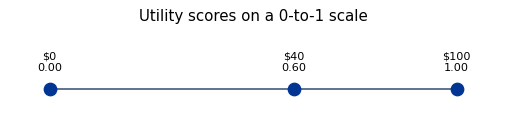

In [15]:
# 🔎 WORKED EXAMPLE — measuring the utility of a sure $40
interview_40 = [
    (0.50, "sure thing"),   # 50% chance at $100? No thanks, I'll keep my $40.
    (0.60, "coin flip"),    # 60%: I honestly can't decide.
    (0.90, "gamble"),       # 90%: I'll take the gamble.
]
p = coin_flip_chance(interview_40)
print(f"Coin flip at p = {p}")
print(f"Score of the gamble at that chance: {p} × 1 + (1 − {p}) × 0 = {gamble_score(p):.2f}")

scores_money = {"$100": 1.0, "$40": p, "$0": 0.0}
check_order(scores_money, ["$100", "$40", "$0"])

# Picture the scores on a 0-to-1 line
fig, ax = plt.subplots(figsize=(7, 1.4))
ax.hlines(0, 0, 1, color="#5A6B8C")
for name, s in scores_money.items():
    ax.plot(s, 0, "o", color="#003594", ms=10)
    ax.text(s, 0.15, f"{name}\n{s:.2f}", ha="center", fontsize=9)
ax.set_xlim(-0.1, 1.1); ax.set_ylim(-0.3, 0.5); ax.axis("off")
ax.set_title("Utility scores on a 0-to-1 scale")
plt.show()

In [16]:
# ✏️ YOUR TURN — Dev's interview (supports Q9)
# The chances are already listed. For each one, copy Dev's choice from the
# Step 4 table in the case study: "sure thing", "gamble" or "coin flip".

dev_interview_X = [(0.30, None), (0.45, None), (0.60, None), (0.80, None), (0.95, None)]
dev_interview_Y = [(0.30, None), (0.45, None), (0.60, None), (0.80, None), (0.95, None)]

# Also enter Dev's corrected ranking (best → worst) from your work in Step 3
dev_ranking = [None, None, None, None]

if ready(dev_interview_X=dev_interview_X, dev_interview_Y=dev_interview_Y, dev_ranking=dev_ranking):
    u_X = coin_flip_chance(dev_interview_X)
    u_Y = coin_flip_chance(dev_interview_Y)
    dev_scores = {dev_ranking[0]: 1.0, "X": u_X, "Y": u_Y, dev_ranking[-1]: 0.0}
    print("U(X) =", u_X, "   U(Y) =", u_Y)
    check_order(dev_scores, dev_ranking)

⏸ Waiting for you: fill in dev_interview_X, dev_interview_Y, dev_ranking then re-run this cell.


> **Q10 and Q11** are reasoning questions. As you answer Q11, think about how many interviews you would need to fill a table like the ones in Step 7, for every student in Oakland.

---
# Step 5: Choose a utility function

The case uses a **Cobb–Douglas** utility function:
$$U(C, H) = C^{\,1-a} \times H^{\,a}$$

and the **budget constraint**
$$C + p \times H = I \quad\Longleftrightarrow\quad C = I - p \times H.$$

Both become one-line Python functions. Every later step uses them.

In [17]:
def utility(C, H, a):
    """Cobb–Douglas utility: C raised to (1 − a), times H raised to a."""
    return C ** (1 - a) * H ** a

def consumption_left(I, p, H):
    """Budget constraint solved for C: money left after paying rent p × H."""
    return I - p * H

### 🔎 Worked example: one utility score, step by step
Jordan (from lecture) has weight **a = 1/3** on housing, so the weight on everything else is 1 − a = 2/3. Score the combination **C = $2,000, H = 500 sq ft**.

In [18]:
# 🔎 WORKED EXAMPLE — computing one utility score by hand, then with the function
a_jordan = 1/3
C, H = 2000, 500

part_C = C ** (1 - a_jordan)          # C raised to 2/3
part_H = H ** a_jordan                # H raised to 1/3
print(f"Weight on housing a = {a_jordan:.3f};  weight on everything else 1 − a = {1 - a_jordan:.3f}")
print(f"C^(1−a) = {C} ** {1 - a_jordan:.3f} = {part_C:.2f}")
print(f"H^a     = {H} ** {a_jordan:.3f} = {part_H:.2f}")
print(f"U = {part_C:.2f} × {part_H:.2f} = {part_C * part_H:.1f}")
print(f"Same thing using the function: utility({C}, {H}, 1/3) = {utility(C, H, a_jordan):.1f}")

Weight on housing a = 0.333;  weight on everything else 1 − a = 0.667
C^(1−a) = 2000 ** 0.667 = 158.74
H^a     = 500 ** 0.333 = 7.94
U = 158.74 × 7.94 = 1259.9
Same thing using the function: utility(2000, 500, 1/3) = 1259.9


### 🔎 Worked example: the three features of the formula
The case lists three features: **weights**, **diminishing returns**, and **needing some of both**. Each can be checked with a quick calculation. (A fourth idea, "utility has no units", is checked at the end.)

In [19]:
# 🔎 WORKED EXAMPLE — Feature 1: weights
# If you double H (keeping C fixed), U gets multiplied by 2 ** a.
# If you double C (keeping H fixed), U gets multiplied by 2 ** (1 − a).
for a in [1/3, 2/3]:
    base = utility(2000, 500, a)
    print(f"a = {a:.2f}:  doubling H multiplies U by {utility(2000, 1000, a) / base:.3f}"
          f"  (= 2 ** {a:.2f});  doubling C multiplies U by {utility(4000, 500, a) / base:.3f}")

a = 0.33:  doubling H multiplies U by 1.260  (= 2 ** 0.33);  doubling C multiplies U by 1.587
a = 0.67:  doubling H multiplies U by 1.587  (= 2 ** 0.67);  doubling C multiplies U by 1.260


,H (sq ft),U,extra U from last 100 sq ft
0,100,736.81,NaN
1,200,928.32,191.51
2,300,"1,062.66",134.34
3,400,"1,169.61",106.95
4,500,"1,259.92",90.31
5,600,"1,338.87",78.94
6,700,"1,409.46",70.59
7,800,"1,473.61",64.15


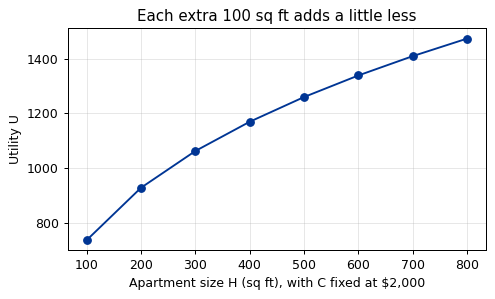

In [20]:
# 🔎 WORKED EXAMPLE — Feature 2: diminishing returns
# Hold C fixed at $2,000 and add space 100 sq ft at a time (a = 1/3).
sizes = [100, 200, 300, 400, 500, 600, 700, 800]
dim = pd.DataFrame({"H (sq ft)": sizes})
dim["U"] = [utility(2000, h, 1/3) for h in sizes]
dim["extra U from last 100 sq ft"] = dim["U"].diff()   # difference from the row above
display(dim)

plt.figure(figsize=(6, 3.2))
plt.plot(dim["H (sq ft)"], dim["U"], "o-", color="#003594")
plt.xlabel("Apartment size H (sq ft), with C fixed at $2,000")
plt.ylabel("Utility U")
plt.title("Each extra 100 sq ft adds a little less")
plt.grid(alpha=0.3); plt.show()

In [21]:
# 🔎 WORKED EXAMPLE — Feature 3: you need some of both
print("Huge apartment, no money left: utility(0, 800, 1/3)  =", utility(0, 800, 1/3))
print("Lots of money, no apartment:   utility(3000, 0, 1/3) =", utility(3000, 0, 1/3))

# Bonus — utility has no units: doubling every score never changes which option is best
options = {"A": (2200, 400), "B": (2000, 500), "C": (1800, 600)}
scores  = {k: utility(C, H, 1/3) for k, (C, H) in options.items()}
doubled = {k: 2 * v for k, v in scores.items()}
print("\nScores:        ", {k: round(v, 1) for k, v in scores.items()}, "→ best:", max(scores, key=scores.get))
print("Doubled scores:", {k: round(v, 1) for k, v in doubled.items()}, "→ best:", max(doubled, key=doubled.get))

Huge apartment, no money left: utility(0, 800, 1/3)  = 0.0
Lots of money, no apartment:   utility(3000, 0, 1/3) = 0.0

Scores:         {'A': 1246.3, 'B': 1259.9, 'C': 1248.1} → best: B
Doubled scores: {'A': 2492.7, 'B': 2519.8, 'C': 2496.1} → best: B


### 🔎 Worked example: the budget constraint
Jordan: budget I = $3,000, price p = $2.00. If Jordan rents 400 sq ft, how much is left for everything else?

In [22]:
# 🔎 WORKED EXAMPLE — budget constraint for Jordan
I_j, p_j, H_j = 3000, 2.00, 400
rent_j = p_j * H_j
print(f"Rent = {H_j} × {money(p_j)} = {money(rent_j)}")
print(f"C = {money(I_j)} − {money(rent_j)} = {money(consumption_left(I_j, p_j, H_j))}")
print(f"General rule for Jordan:  C = {I_j:,} − {p_j:.2f} × H")

Rent = 400 × $2.00 = $800.00
C = $3,000.00 − $800.00 = $2,200.00
General rule for Jordan:  C = 3,000 − 2.00 × H


In [23]:
# ✏️ YOUR TURN — Dev's budget constraint (supports Q13)
dev_I = None   # Dev's monthly budget
dev_p = None   # today's rent per square foot
H_q13 = None   # the apartment size named in Q13

if ready(dev_I=dev_I, dev_p=dev_p, H_q13=H_q13):
    print(f"Rent = {H_q13} × {money(dev_p)} = {money(dev_p * H_q13)}")
    print(f"C = {money(consumption_left(dev_I, dev_p, H_q13))}")
    print(f"General rule for Dev:  C = {dev_I:,} − {dev_p:.2f} × H")

⏸ Waiting for you: fill in dev_I, dev_p, H_q13 then re-run this cell.


---
# Step 6: Estimate the weight from data

The case tells you a key fact: someone who maximizes Cobb–Douglas utility spends exactly the share **a** of their budget on housing. (You will check this claim yourself in Step 7.) So to estimate **a**, you:

1. compute each person's **housing share** = rent ÷ budget,
2. take the **average** share, and
3. use that average as **a** (and 1 − a as the other weight).

It is also worth looking at the **spread**: the lowest and highest shares. No statistics needed, just `min` and `max`.

### 🔎 Worked example: a practice survey
Five (fictional) graduate students in another neighborhood were surveyed. These are **not** the case study's students.

In [24]:
# 🔎 WORKED EXAMPLE — estimating a from a practice survey
practice = pd.DataFrame({
    "student": ["Priya", "Marco", "Lena", "Tom", "Ruth"],
    "budget":  [2400, 3000, 2700, 3300, 3600],
    "rent":    [768, 1020, 891, 1056, 1224],
})

# Step 1: each person's share = rent ÷ budget
practice["share"] = practice["rent"] / practice["budget"]
display(practice.style.format({"budget": "${:,.0f}", "rent": "${:,.0f}", "share": "{:.0%}"}))

# Step 2: average share (add up, divide by how many)
total = practice["share"].sum()
count = len(practice)
a_practice = total / count
print(f"Average share = {total:.2f} ÷ {count} = {a_practice:.3f}  ({a_practice:.0%})")

# Step 3: the weights
print(f"Estimated a = {a_practice:.2f};  weight on everything else 1 − a = {1 - a_practice:.2f}")
print(f"Utility function: U = C^{1 - a_practice:.2f} × H^{a_practice:.2f}")

# Spread: how different are the people?
print(f"Lowest share {practice['share'].min():.0%}, highest {practice['share'].max():.0%}")

,student,budget,rent,share
0,Priya,"$2,400",$768,32%
1,Marco,"$3,000","$1,020",34%
2,Lena,"$2,700",$891,33%
3,Tom,"$3,300","$1,056",32%
4,Ruth,"$3,600","$1,224",34%


Average share = 1.65 ÷ 5 = 0.330  (33%)
Estimated a = 0.33;  weight on everything else 1 − a = 0.67
Utility function: U = C^0.67 × H^0.33
Lowest share 32%, highest 34%


In [25]:
# 🔎 WORKED EXAMPLE — how well does the average fit each individual?
# Predicted rent for each person = a × their budget. Compare with what they actually pay.
practice["predicted rent"] = a_practice * practice["budget"]
practice["actual − predicted"] = practice["rent"] - practice["predicted rent"]
display(practice[["student", "budget", "rent", "predicted rent", "actual − predicted"]]
        .style.format({"budget": "${:,.0f}", "rent": "${:,.0f}",
                       "predicted rent": "${:,.2f}", "actual − predicted": "${:,.2f}"}))

,student,budget,rent,predicted rent,actual − predicted
0,Priya,"$2,400",$768,$792.00,$-24.00
1,Marco,"$3,000","$1,020",$990.00,$30.00
2,Lena,"$2,700",$891,$891.00,$0.00
3,Tom,"$3,300","$1,056","$1,089.00",$-33.00
4,Ruth,"$3,600","$1,224","$1,188.00",$36.00


In [26]:
# ✏️ YOUR TURN — the task force's survey (supports Q14 and Q15; useful for Q16)
# Copy each student's budget and rent from the Step 6 table in the case study.

survey = pd.DataFrame({
    "student": ["Ana", "Ben", "Carmen", "Darius", "Elena", "Felix"],
    "budget":  [None, None, None, None, None, None],
    "rent":    [None, None, None, None, None, None],
})

if ready(budget=list(survey["budget"]), rent=list(survey["rent"])):
    survey["share"] = survey["rent"] / survey["budget"]
    display(survey.style.format({"budget": "${:,.0f}", "rent": "${:,.0f}", "share": "{:.0%}"}))
    a_estimate = survey["share"].sum() / len(survey)
    print(f"Average share = {a_estimate:.3f}")
    print(f"Lowest share {survey['share'].min():.0%}, highest {survey['share'].max():.0%}")
    # Uncomment the next lines to compare predictions with each student (useful for Q16):
    # survey["predicted rent"] = a_estimate * survey["budget"]
    # survey["actual − predicted"] = survey["rent"] - survey["predicted rent"]
    # display(survey)

⏸ Waiting for you: fill in budget, rent then re-run this cell.


---
# Step 7: Find the best apartment

To **optimize**, list several apartment sizes and, for each one, compute:

| Column | Formula |
|---|---|
| rent | p × H |
| C | I − rent |
| U | C<sup>1−a</sup> × H<sup>a</sup> |

Then pick the row with the **largest U**. The function below builds that table for any budget, price and weight, so you can reuse it for every "what if" in Step 8.

In [27]:
def utility_table(I, p, a, sizes):
    """Build the table from the case: size, rent, C and U for each size."""
    t = pd.DataFrame({"H (sq ft)": sizes})
    t["rent"] = p * t["H (sq ft)"]
    t["C"] = I - t["rent"]
    t["U"] = utility(t["C"], t["H (sq ft)"], a)
    return t

def best_row(table):
    """Return the row with the largest utility."""
    return table.loc[table["U"].idxmax()]

def best_by_search(I, p, a, step=1):
    """Check every size from `step` up to what the budget allows, 1 sq ft at a time,
    and return the best size, its rent, and the share of the budget spent on rent."""
    sizes = [h for h in range(step, int(I / p), step)]
    t = utility_table(I, p, a, sizes)
    b = best_row(t)
    return {"I": I, "p": p, "best H": int(b["H (sq ft)"]), "rent": round(float(b["rent"]), 2),
            "share": round(float(b["rent"]) / I, 4)}

### 🔎 Worked example: Jordan's best apartment
Jordan: **I = $3,000**, **p = $2.00**, **a = 1/3**. First a warm-up row, done by hand; then the full table.

In [28]:
# 🔎 WORKED EXAMPLE — warm-up: one row of Jordan's table, every step shown
I_j, p_j, a_j, H = 3000, 2.00, 1/3, 400

rent = H * p_j;                 print(f"(a) Rent    = {H} × {money(p_j)} = {money(rent)}")
C = I_j - rent;                 print(f"(b) C       = {money(I_j)} − {money(rent)} = {money(C)}")
part_C = C ** (1 - a_j);        print(f"(c) C^(1−a) = {C:,.0f} ** {1 - a_j:.3f} = {part_C:.2f}")
part_H = H ** a_j;              print(f"(d) H^a     = {H} ** {a_j:.3f} = {part_H:.2f}")
print(f"(e) U       = {part_C:.2f} × {part_H:.2f} = {part_C * part_H:.1f}")

(a) Rent    = 400 × $2.00 = $800.00
(b) C       = $3,000.00 − $800.00 = $2,200.00
(c) C^(1−a) = 2,200 ** 0.667 = 169.15
(d) H^a     = 400 ** 0.333 = 7.37
(e) U       = 169.15 × 7.37 = 1246.3


In [29]:
# 🔎 WORKED EXAMPLE — Jordan's full table and best choice
jordan_table = utility_table(I=3000, p=2.00, a=1/3, sizes=[300, 400, 500, 600, 700])
display(jordan_table.style.format({"rent": "${:,.0f}", "C": "${:,.0f}", "U": "{:.1f}"})
        .highlight_max(subset="U", color="#FFF4D6"))

b = best_row(jordan_table)
print(f"Best size: {b['H (sq ft)']:.0f} sq ft, rent {money(b['rent'])}")
print(f"Share of budget on rent: {money(b['rent'])} ÷ $3,000.00 = {b['rent'] / 3000:.3f}")

,H (sq ft),rent,C,U
0,300,$600,"$2,400",1200.0
1,400,$800,"$2,200",1246.3
2,500,"$1,000","$2,000",1259.9
3,600,"$1,200","$1,800",1248.1
4,700,"$1,400","$1,600",1214.6


Best size: 500 sq ft, rent $1,000.00
Share of budget on rent: $1,000.00 ÷ $3,000.00 = 0.333


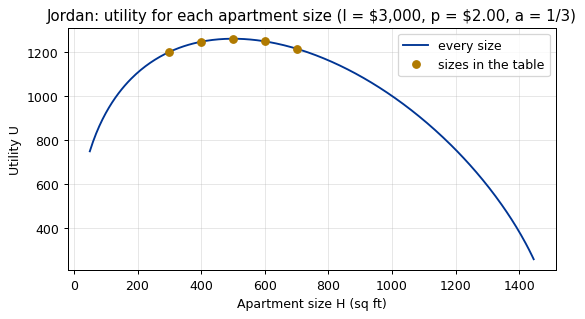

In [30]:
# 🔎 WORKED EXAMPLE — the same model drawn as a curve
# Every size from 50 to 1,450 sq ft, with the table's sizes marked as dots.
curve = utility_table(3000, 2.00, 1/3, list(range(50, 1450, 5)))
plt.figure(figsize=(7, 3.5))
plt.plot(curve["H (sq ft)"], curve["U"], color="#003594", label="every size")
plt.plot(jordan_table["H (sq ft)"], jordan_table["U"], "o", color="#B07A00", label="sizes in the table")
plt.xlabel("Apartment size H (sq ft)"); plt.ylabel("Utility U")
plt.title("Jordan: utility for each apartment size (I = $3,000, p = $2.00, a = 1/3)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

In [31]:
# 🔎 WORKED EXAMPLE — how much utility do you lose by choosing a different row?
# Percentage loss = (best U − other U) ÷ best U
best_U = best_row(jordan_table)["U"]
jordan_table["% below best"] = (best_U - jordan_table["U"]) / best_U
display(jordan_table.style.format({"rent": "${:,.0f}", "C": "${:,.0f}", "U": "{:.1f}", "% below best": "{:.1%}"}))

,H (sq ft),rent,C,U,% below best
0,300,$600,"$2,400",1200.0,4.8%
1,400,$800,"$2,200",1246.3,1.1%
2,500,"$1,000","$2,000",1259.9,0.0%
3,600,"$1,200","$1,800",1248.1,0.9%
4,700,"$1,400","$1,600",1214.6,3.6%


In [32]:
# 🔎 WORKED EXAMPLE — testing the "share = a" claim in many situations (a = 1/3)
# Search every size, 1 sq ft at a time, for several budgets and prices.
# (Shares can differ from a by a hair because the search only tries whole square feet.)
checks = pd.DataFrame([best_by_search(I, p, 1/3) for I, p in
                       [(2000, 1.50), (3000, 2.00), (3000, 3.00), (4500, 2.00), (6000, 2.50)]])
display(checks.style.format({"I": "${:,.0f}", "p": "${:.2f}", "best H": "{:,.0f}",
                             "rent": "${:,.0f}", "share": "{:.3f}"}))

,I,p,best H,rent,share
0,"$2,000",$1.50,444,$666,0.333
1,"$3,000",$2.00,500,"$1,000",0.333
2,"$3,000",$3.00,333,$999,0.333
3,"$4,500",$2.00,750,"$1,500",0.333
4,"$6,000",$2.50,800,"$2,000",0.333


In [33]:
# ✏️ YOUR TURN — the warm-up row for Dev (supports Q17)
# Use a = 0.4 as the case instructs, and Dev's budget and price from Step 7.

I_dev = None
p_dev = None
a_dev = None
H_warm = None    # the size used in the Q17 warm-up

if ready(I_dev=I_dev, p_dev=p_dev, a_dev=a_dev, H_warm=H_warm):
    rent = H_warm * p_dev;      print(f"(a) Rent    = {money(rent)}")
    C = I_dev - rent;           print(f"(b) C       = {money(C)}")
    part_C = C ** (1 - a_dev);  print(f"(c) C^(1−a) = {part_C:.2f}")
    part_H = H_warm ** a_dev;   print(f"(d) H^a     = {part_H:.2f}")
    print(f"(e) U       = {part_C * part_H:.1f}")

⏸ Waiting for you: fill in I_dev, p_dev, a_dev, H_warm then re-run this cell.


In [34]:
# ✏️ YOUR TURN — Dev's full table (supports Q18, Q19 and Q20)
# Copy the list of sizes from the Q18 table, e.g. [100, 200, ...]
dev_sizes = None
compare_size = None   # for Q20: a size to compare against the best one

if ready(I_dev=I_dev, p_dev=p_dev, a_dev=a_dev, dev_sizes=dev_sizes):
    dev_table = utility_table(I_dev, p_dev, a_dev, dev_sizes)
    display(dev_table.style.format({"rent": "${:,.0f}", "C": "${:,.0f}", "U": "{:.1f}"}))
    b = best_row(dev_table)
    print(f"Largest U in the table: {b['U']:.1f} at {b['H (sq ft)']:.0f} sq ft (rent {money(b['rent'])})")
    print(f"Share of budget on rent: {b['rent'] / I_dev:.3f}")
    if compare_size is not None:
        other = utility(consumption_left(I_dev, p_dev, compare_size), compare_size, a_dev)
        print(f"U at {compare_size} sq ft = {other:.1f};  % below best = {(b['U'] - other) / b['U']:.1%}")

⏸ Waiting for you: fill in I_dev, p_dev, a_dev, dev_sizes then re-run this cell.


---
# Step 8: Ask "what if?"

A "what if" means **changing one input and solving again**. The utility function (and so **a**) stays the same, because a price or income change does not change what a person *likes*, only what they can *afford*.

The case also gives a **shortcut** that follows from the share rule:
$$\text{best rent} = a \times I \qquad\qquad \text{best size} = \frac{a \times I}{p}$$

In [35]:
def best_rent(a, I):
    """Shortcut: an optimizer spends the share a of the budget on rent."""
    return a * I

def best_size(a, I, p):
    """Shortcut: best size = (a × I) ÷ p."""
    return a * I / p

### 🔎 Worked example A: Jordan's rent rises to $2.40
Same budget ($3,000) and weight (1/3); only the price changes. Notice that the best size in a coarse table may fall *between* the rows, so we also run the 1-sq-ft search and the shortcut.

In [36]:
# 🔎 WORKED EXAMPLE A — price change for Jordan
table_A = utility_table(I=3000, p=2.40, a=1/3, sizes=[300, 350, 400, 450, 500])
display(table_A.style.format({"rent": "${:,.0f}", "C": "${:,.0f}", "U": "{:.1f}"})
        .highlight_max(subset="U", color="#FFF4D6"))

print("Fine search (every 1 sq ft):", best_by_search(3000, 2.40, 1/3))
print(f"Shortcut: best rent = 1/3 × $3,000 = {money(best_rent(1/3, 3000))};"
      f"  best size = {money(best_rent(1/3, 3000))} ÷ $2.40 = {best_size(1/3, 3000, 2.40):.1f} sq ft")

,H (sq ft),rent,C,U
0,300,$720,"$2,280",1159.7
1,350,$840,"$2,160",1177.6
2,400,$960,"$2,040",1185.2
3,450,"$1,080","$1,920",1183.8
4,500,"$1,200","$1,800",1174.5


Fine search (every 1 sq ft): {'I': 3000, 'p': 2.4, 'best H': 417, 'rent': 1000.8, 'share': 0.3336}
Shortcut: best rent = 1/3 × $3,000 = $1,000.00;  best size = $1,000.00 ÷ $2.40 = 416.7 sq ft


In [37]:
# 🔎 WORKED EXAMPLE A (continued) — the utility of a rule-follower
# Casey keeps 500 sq ft at the new price. Score Casey's combination with Jordan's
# utility function, then compare it with the best possible score.
casey_H = 500
casey_C = consumption_left(3000, 2.40, casey_H)
casey_U = utility(casey_C, casey_H, 1/3)
best_U_A = utility(consumption_left(3000, 2.40, best_size(1/3, 3000, 2.40)), best_size(1/3, 3000, 2.40), 1/3)

print(f"Casey: H = {casey_H} sq ft, C = {money(casey_C)}, U = {casey_U:.1f}")
print(f"Best possible at $2.40: U = {best_U_A:.1f}")
print(f"Difference: {best_U_A - casey_U:.1f} points, or {(best_U_A - casey_U) / best_U_A:.1%} below best")

Casey: H = 500 sq ft, C = $1,800.00, U = 1174.5
Best possible at $2.40: U = 1185.6
Difference: 11.2 points, or 0.9% below best


### 🔎 Worked example B: Jordan gets a raise
Price returns to $2.00; Jordan's budget rises to **$3,600**.

In [38]:
# 🔎 WORKED EXAMPLE B — income change for Jordan, three ways
I_new = 3600
print(f"Shortcut: rent = 1/3 × {money(I_new)} = {money(best_rent(1/3, I_new))};"
      f"  size = {money(best_rent(1/3, I_new))} ÷ $2.00 = {best_size(1/3, I_new, 2.00):.0f} sq ft")
print("Fine search:", best_by_search(I_new, 2.00, 1/3))

table_B = utility_table(I=I_new, p=2.00, a=1/3, sizes=[500, 550, 600, 650, 700])
display(table_B.style.format({"rent": "${:,.0f}", "C": "${:,.0f}", "U": "{:.1f}"})
        .highlight_max(subset="U", color="#FFF4D6"))

# What do Jordan's rule-following housemates do after the same raise?
display(pd.DataFrame([fixed_size_rule(500, 2.00, I_new), fixed_rent_rule(1000, 2.00, I_new)],
                     index=["Casey (fixed size)", "Taylor (fixed rent)"]))

Shortcut: rent = 1/3 × $3,600.00 = $1,200.00;  size = $1,200.00 ÷ $2.00 = 600 sq ft
Fine search: {'I': 3600, 'p': 2.0, 'best H': 600, 'rent': 1200.0, 'share': 0.3333}


,H (sq ft),rent,C,U
0,500,"$1,000","$2,600",1500.7
1,550,"$1,100","$2,500",1509.2
2,600,"$1,200","$2,400",1511.9
3,650,"$1,300","$2,300",1509.3
4,700,"$1,400","$2,200",1501.9


,size (sq ft),rent,left for everything else
Casey (fixed size),500.00,"1,000.00","2,600.00"
Taylor (fixed rent),500.00,"1,000.00","2,600.00"


In [39]:
# ✏️ YOUR TURN — What if A: Dev's rent rises (supports Q21)
p_new = None       # the new price per square foot
sizes_A = None     # copy the sizes from the Q21 table

if ready(I_dev=I_dev, a_dev=a_dev, p_new=p_new, sizes_A=sizes_A):
    dev_A = utility_table(I_dev, p_new, a_dev, sizes_A)
    display(dev_A.style.format({"rent": "${:,.0f}", "C": "${:,.0f}", "U": "{:.1f}"}))
    b = best_row(dev_A)
    print(f"Largest U in the table: {b['U']:.1f} at {b['H (sq ft)']:.0f} sq ft (rent {money(b['rent'])})")

⏸ Waiting for you: fill in I_dev, a_dev, p_new, sizes_A then re-run this cell.


In [40]:
# ✏️ YOUR TURN — Riley's utility after the price rise (supports Q23)
riley_H = None     # the size Riley keeps
riley_C = None     # what Riley has left for everything else (see Q23)

if ready(riley_H=riley_H, riley_C=riley_C, a_dev=a_dev):
    riley_U = utility(riley_C, riley_H, a_dev)
    print(f"Riley's utility: {riley_U:.1f}")
    # Compare with Dev's best from the previous cell:
    if 'dev_A' in globals():
        top = best_row(dev_A)["U"]
        print(f"Dev's best: {top:.1f};  difference {top - riley_U:.1f} points ({(top - riley_U) / top:.1%})")

⏸ Waiting for you: fill in riley_H, riley_C, a_dev then re-run this cell.


In [41]:
# ✏️ YOUR TURN — What if B: Dev gets a raise (supports Q24 and Q25)
I_raise = None     # Dev's new budget
p_back  = None     # the price in What if B
sam_rent_B = None  # the rent Sam always pays

if ready(I_raise=I_raise, p_back=p_back, a_dev=a_dev):
    print(f"Shortcut: best rent = {money(best_rent(a_dev, I_raise))};  best size = {best_size(a_dev, I_raise, p_back):.0f} sq ft")
    print("Fine-search check:", best_by_search(I_raise, p_back, a_dev))
    if sam_rent_B is not None:
        display(pd.DataFrame([fixed_rent_rule(sam_rent_B, p_back, I_raise)], index=["Sam"]))

⏸ Waiting for you: fill in I_raise, p_back, a_dev then re-run this cell.


> **Now go back to Q2.** Compare your guess with what the model says. Q22 and the second half of Q25 are for you to answer in words.

---
# Step 9: Test the model and find its limits

Two kinds of calculation help here:

1. **How often was the prediction right?** Count the people who did roughly what the model predicted and divide by the total.
2. **Pushing to the extremes.** Use the shortcut at very low and very high budgets and look at whether the predicted apartments are believable.

In [42]:
# 🔎 WORKED EXAMPLE — percentage of correct predictions (practice numbers)
practice_followup = {"did what the model predicted": 18,
                     "did something else": 7}
total = sum(practice_followup.values())
right = practice_followup["did what the model predicted"]
print(f"{right} of {total} = {right / total:.0%} matched the prediction")

18 of 25 = 72% matched the prediction


In [43]:
# 🔎 WORKED EXAMPLE — the shortcut at extreme budgets (a = 1/3, p = $2.00)
extremes = pd.DataFrame({"budget I": [900, 1500, 3000, 6000, 15000, 50000]})
extremes["predicted rent (a × I)"] = best_rent(1/3, extremes["budget I"])
extremes["predicted size (sq ft)"] = best_size(1/3, extremes["budget I"], 2.00)
display(extremes.style.format({"budget I": "${:,.0f}", "predicted rent (a × I)": "${:,.0f}",
                               "predicted size (sq ft)": "{:,.0f}"}))

,budget I,predicted rent (a × I),predicted size (sq ft)
0,$900,$300,150
1,"$1,500",$500,250
2,"$3,000","$1,000",500
3,"$6,000","$2,000","1,000"
4,"$15,000","$5,000","2,500"
5,"$50,000","$16,667","8,333"


In [44]:
# ✏️ YOUR TURN — the follow-up survey (supports Q26)
# Decide which group(s) in the Step 9 table behaved as the model predicted.
matched = None   # number of students whose behavior matched the prediction
surveyed = None  # total number of students surveyed

if ready(matched=matched, surveyed=surveyed):
    print(f"{matched} of {surveyed} = {matched / surveyed:.0%}")

⏸ Waiting for you: fill in matched, surveyed then re-run this cell.


In [45]:
# ✏️ YOUR TURN — Dev's model at the extremes (supports Q29)
p_extreme = None                    # price per sq ft used in Q29
extreme_budgets = [None, None]      # the two budgets named in Q29

if ready(a_dev=a_dev, p_extreme=p_extreme, extreme_budgets=extreme_budgets):
    for I_x in extreme_budgets:
        print(f"Budget {money(I_x)}: predicted rent {money(best_rent(a_dev, I_x))}, "
              f"predicted size {best_size(a_dev, I_x, p_extreme):,.0f} sq ft")

⏸ Waiting for you: fill in a_dev, p_extreme, extreme_budgets then re-run this cell.


> **Q27, Q28 and Q30** are reasoning questions. A useful prompt for Q28: look back at the inputs of `utility_table`. What choices does the model let a person make, and what choices does it leave out?

---
# Wrap-up: what you built

You built a complete rational actor model out of a handful of small tools:

| Step | Tool | What it does |
|---|---|---|
| 1 | `fixed_size_rule`, `fixed_rent_rule` | Predict rule-based actors |
| 3 | `draw_preferences`, `find_loops`, `rank_by_wins`, `money_pump` | Check whether preferences can be ranked at all |
| 4 | `coin_flip_chance`, `gamble_score`, `check_order` | Measure utility on a 0-to-1 scale |
| 5 | `utility`, `consumption_left` | The Cobb–Douglas utility function and the budget constraint |
| 6 | share, average, min/max | Estimate the weight *a* from people's choices |
| 7 | `utility_table`, `best_row`, `best_by_search` | Find the best choice by comparing options |
| 8 | `best_rent`, `best_size` | The shortcut for "what if?" questions |

The same workflow (state assumptions, check preferences, choose a form, estimate, optimize, ask "what if", test) applies far beyond housing. Try changing the worked examples: a different weight, a different budget, a different price. Then write your answers to the case questions on your worksheet, in your own words.